# Intro

In [1]:
ALPHA=0.01

## Modules

### Standard

In [2]:
import os, pickle, platform, sys, json
import numpy as np
import copy
import torch

In [3]:
from collections import defaultdict

In [4]:
import dcms
from dcms.models import DCMModel, DECMModel, qDECMModel, DWCMModel

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['xtick.major.size'] = 10
plt.rcParams['xtick.major.width'] = 2
plt.rcParams['ytick.major.size'] = 10
plt.rcParams['ytick.major.width'] = 2

plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14

plt.rcParams['xtick.minor.size'] = 5
plt.rcParams['xtick.minor.width'] = 1
plt.rcParams['ytick.minor.size'] = 5
plt.rcParams['ytick.minor.width'] = 1
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
from matplotlib.ticker import ScalarFormatter

In [6]:
from scipy.stats import spearmanr

In [7]:
from tqdm.notebook import tqdm, trange

In [8]:
import datetime as dt

In [9]:
from bowtie import edges2bowtie

In [10]:
from tabulate import tabulate

### Home made

In [11]:
if platform.system() == 'Darwin':
    print('Air!')
    HOME = '/Users/fabio/Documents/Lavoro/PythonFiles/bowtie2_py310/bowtie2/'
elif platform.system() == 'Linux':
    print('Stella!')
    HOME = '/home/sarawalk/bowtie2_py39/bowtie2/'
else:
    raise RuntimeError(f"Unsupported OS: {platform.system()}")

sys.path.insert(0, HOME)

Air!


In [12]:
from bowtie_plot_functions import plot_bowtie_blocks, plot_bowtie_fluxes, _add_colorbar
from bowtie_plot_functions import _fdr as fdr

## Folders

In [13]:
DATA_FOLDER=HOME+'dati_elezioni/'
TEST_FOLDER=HOME+'tests/'
GUARINO_FOLDER=HOME+'guarino_files/'
BIPARTITE_FOLDER=HOME+'BiDCM/'
PLOT_FOLDER=HOME+'plots/'

In [14]:
if platform.system() == 'Darwin':
    os.system("afplay ta-da.mp3")
    PVALUE_FOLDER = '/Users/fabio/Documents/Lavoro/PythonFiles/bowtie2_py310/benchmark_19/results_final/pvalues/'
elif platform.system() == 'Linux':
    
    PVALUE_FOLDER = '/home/sarawalk/bowtie2_py39/bowtie2/benchmark_19/results_final/pvalues/'
else:
    raise RuntimeError(f"Unsupported OS: {platform.system()}")


## Names for $\LaTeX$
#### Names as in the draft

In [15]:
def parse_dico_names(filepath):
    with open(filepath, 'r') as f:
        lines = [line.strip().split() for line in f]
        # such a command creates a list
        # in which each element is a list of tokens of a line in the file
        # remarkably, there is an empty element
        # before each dataset name
        

    result = {}
    current_key = None

    for tokens in lines:
        if not tokens:
            current_key = None
        elif current_key is None:
            # prima riga non vuota del gruppo: nome del dataset
            current_key = tokens[0]
            result[current_key] = {}
        else:
            # riga tipo ['5:', 'journalists', '&', 'Media']
            idx = int(tokens[0].rstrip(':'))
            label = ' '.join(tokens[1:])
            result[current_key][idx] = label

    return result

In [16]:
cacca=parse_dico_names(GUARINO_FOLDER+'all_dico_labels.txt')

In [17]:
name_changer={'c0': 'Crisis - Centrists', 'c1': 'Crisis - Centre-right', 'c2': 'Crisis - M5S', 'c3': 'Crisis - PD', 'c4': 'Crisis - Media', 'e0': 'Elections - Centre-right', 'e1': 'Elections - Centre-left', 'e2': 'Elections - M5S', 'e3': 'Elections - Centrists', 'e4': 'Elections - Others', 'e5': 'Elections - Media', 'e6': 'Elections - Others 2', 'p0': 'President -  Centrists', 'p1': 'President -  PD', 'p2': 'President -  M5S', 'p3': 'President -  Media', 'p4': 'President -  Right', 'p5': 'President -  Others', 'p6': 'President -  FI'}

#### Proper scientific notation for the Latex table

In [18]:
def sci_latex(x, dec=2, bold=False):
    # da Claude
    mant, exp = f'{x:.{dec}e}'.split('e')
    if bold:
        return f'$\\mathbf{{{mant}\\times 10^{{{int(exp)}}}}}$'
    return f'${mant}\\times 10^{{{int(exp)}}}$'


## Functions

In [19]:
def p_value_right_tail(count_sample, obs, l_sample):
    """
    Compute the empirical p-value based on the count sample and observed value.

    Parameters:
    count_sample (array-like): The sample of counts from the null distribution.
    obs (float): The observed value to compare against the null distribution.
    l_sample (int): The number of samples in count_sample.

    Returns:
    float: The empirical p-value.
    """
    if len(count_sample) == 0:
        return 1.0
    else:
        return (np.sum(np.array(count_sample) > obs) + 1) / (l_sample + 1)

# Blocks

In [20]:
models=['dwcm', 'qdecm', 'decm']

In [21]:
datasets=[]
block_p_values = defaultdict(dict)
for model in models:
    subfolder=PVALUE_FOLDER+f"{model}/"
    files=[f for f in os.listdir(subfolder) if 'block' in f]
    files.sort()
    for file in files:
        # proper name
        if 'elections' in file.lower():
            name='e'
        elif 'crisi' in file.lower():
            name='c'
        elif 'quirinale' in file.lower():
            name='p'
        else:
            print(f"Unknown dataset in solution {file}. Skipping.")
            continue
        
        try:
            i_dico=file.index('dico')
            dico=file[i_dico+4]
        except ValueError:
            print(f"No 'dico' found in solution {file}. Skipping.")
            continue
    
        dataset=f"{name}{dico}"
        if dataset=='e6':
            # for this network, the bowtie is degenerate, so we skip it
            continue
        datasets.append(dataset)
        block_p_values[dataset][model] = {}


        with open(subfolder+file, 'rb') as f:
            _aux = pickle.load(f)
        for key in _aux.keys():
            # acutally, the test should be two-tailed for blocks
            p_value = p_value_right_tail(_aux[key]['count_sample'], _aux[key]['obs'], 5000)
            block_p_values[dataset][model][key] = p_value

### All together now

In [22]:
blocks=list(block_p_values['c0']['dwcm'].keys())
blocks.sort()
n_blocks = len(blocks)

In [23]:
blocks

['IN', 'INTENDRILS', 'OTHERS', 'OUT', 'OUTTENDRILS', 'SCC', 'TUBES']

In [24]:
dwcm_p_values=[block_p_values[dataset]['dwcm'][key] for dataset in datasets for key in blocks]
decm_p_values=[block_p_values[dataset]['decm'][key] for dataset in datasets for key in blocks]
qdecm_p_values=[block_p_values[dataset]['qdecm'][key] for dataset in datasets for key in blocks]

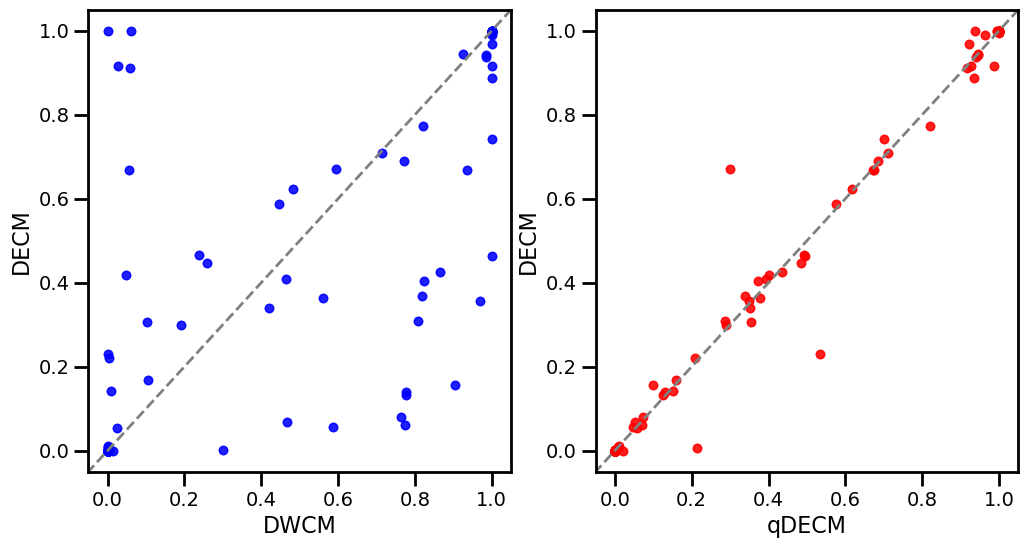

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].scatter(dwcm_p_values, decm_p_values, color='blue', alpha=0.5, label='DWCM vs DECM')
axs[1].scatter(qdecm_p_values, decm_p_values, color='red', alpha=0.5, label='qDECM vs DECM')
for i in range(2):
    axs[i].plot([-2, 2], [-2, 2], '--', lw=2, color='gray')
    axs[i].set_xlim(-0.05, 1.05)
    axs[i].set_ylim(-0.05, 1.05)
axs[0].set_xlabel('DWCM', fontsize=16)
axs[0].set_ylabel('DECM', fontsize=16)
axs[1].set_xlabel('qDECM', fontsize=16)
axs[1].set_ylabel('DECM', fontsize=16)
plt.show()

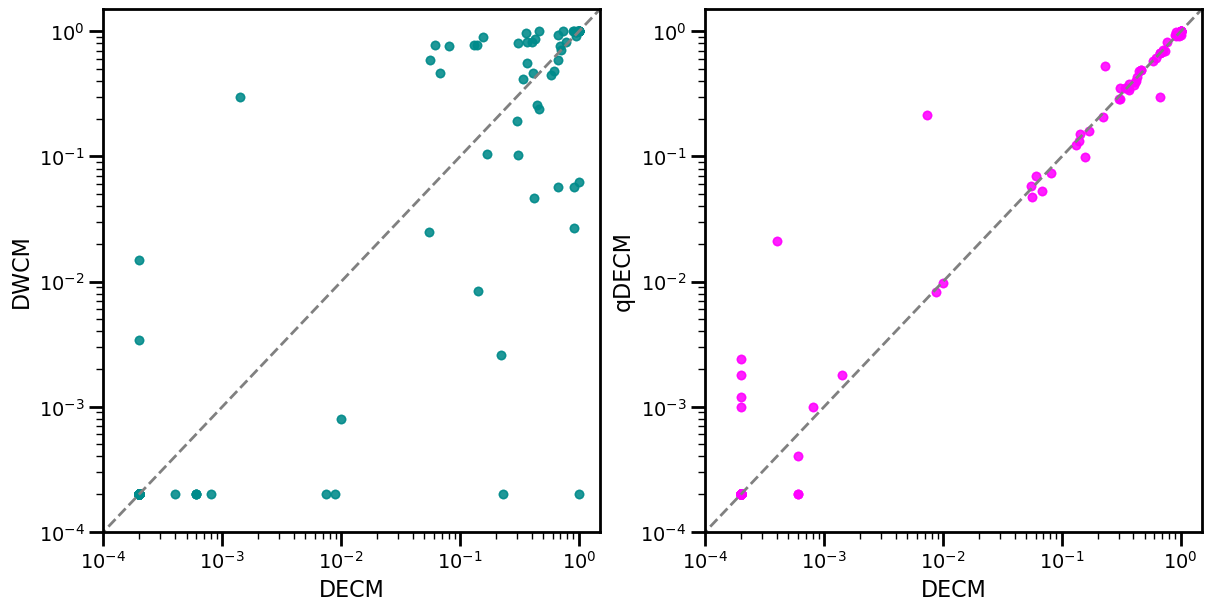

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6),layout="constrained")
axs[0].scatter(decm_p_values,dwcm_p_values, color='darkcyan', alpha=0.5)
axs[1].scatter(decm_p_values,qdecm_p_values, color='magenta', alpha=0.5)
for i in range(2):
    axs[i].plot([1e-5, 2], [1e-5, 2], '--', lw=2, color='gray')
                
    axs[i].set_xlim(1e-4, 1.5)
    axs[i].set_ylim(1e-4, 1.5)
    axs[i].set_xscale('log')
    axs[i].set_yscale('log')
    #axs[i].legend(fontsize=16)
axs[0].set_xlabel('DECM', fontsize=16)
axs[0].set_ylabel('DWCM', fontsize=16)
axs[1].set_xlabel('DECM', fontsize=16)
axs[1].set_ylabel('qDECM', fontsize=16)
plt.savefig(PLOT_FOLDER+f"p_value_block_comparison.png", dpi=300)
plt.show()

## Debug: why excluding e6?

In [27]:
for model in models:
    subfolder=PVALUE_FOLDER+f"{model}/"
    files=[f for f in os.listdir(subfolder) if 'block' in f]
    files.sort()
    for file in files:
        # proper name
        if 'elections' in file.lower():
            name='e'
        elif 'crisi' in file.lower():
            name='c'
        elif 'quirinale' in file.lower():
            name='p'
        else:
            print(f"Unknown dataset in solution {file}. Skipping.")
            continue
        
        try:
            i_dico=file.index('dico')
            dico=file[i_dico+4]
        except ValueError:
            print(f"No 'dico' found in solution {file}. Skipping.")
            continue
        
        dataset=f"{name}{dico}"
        if dataset!='e6':
            continue
        else:
            with open(subfolder+file, 'rb') as f:
                _aux = pickle.load(f)

In [28]:
_aux['SCC']['obs']

1

# Flows

In [29]:
models=['dwcm', 'qdecm', 'decm']

In [30]:
flow_p_values = defaultdict(dict)
for model in models:
    subfolder=PVALUE_FOLDER+f"{model}/"
    files=[f for f in os.listdir(subfolder) if 'flux' in f]
    files.sort()
    for file in files:
        # proper name
        if 'elections' in file.lower():
            name='e'
        elif 'crisi' in file.lower():
            name='c'
        elif 'quirinale' in file.lower():
            name='p'
        else:
            print(f"Unknown dataset in solution {file}. Skipping.")
            continue
        
        try:
            i_dico=file.index('dico')
            dico=file[i_dico+4]
        except ValueError:
            print(f"No 'dico' found in solution {file}. Skipping.")
            continue
    
        dataset=f"{name}{dico}"
        if dataset=='e6':
            # for this network, the bowtie is degenerate, so we skip it
            continue
                
        flow_p_values[dataset][model] = {}


        with open(subfolder+file, 'rb') as f:
            _aux = pickle.load(f)
        for key in _aux.keys():
            p_value = p_value_right_tail(_aux[key]['count_sample'], _aux[key]['obs'], 5000)
            flow_p_values[dataset][model][key] = p_value

### All together now

In [31]:
flows=list(flow_p_values['c0']['dwcm'].keys())
flows.sort()
n_flows = len(flows)

In [32]:
flows

['IN->IN',
 'IN->INTENDRILS',
 'IN->OTHERS',
 'IN->OUT',
 'IN->OUTTENDRILS',
 'IN->SCC',
 'IN->TUBES',
 'INTENDRILS->IN',
 'INTENDRILS->INTENDRILS',
 'INTENDRILS->OTHERS',
 'INTENDRILS->OUT',
 'INTENDRILS->OUTTENDRILS',
 'INTENDRILS->SCC',
 'INTENDRILS->TUBES',
 'OTHERS->IN',
 'OTHERS->INTENDRILS',
 'OTHERS->OTHERS',
 'OTHERS->OUT',
 'OTHERS->OUTTENDRILS',
 'OTHERS->SCC',
 'OTHERS->TUBES',
 'OUT->IN',
 'OUT->INTENDRILS',
 'OUT->OTHERS',
 'OUT->OUT',
 'OUT->OUTTENDRILS',
 'OUT->SCC',
 'OUT->TUBES',
 'OUTTENDRILS->IN',
 'OUTTENDRILS->INTENDRILS',
 'OUTTENDRILS->OTHERS',
 'OUTTENDRILS->OUT',
 'OUTTENDRILS->OUTTENDRILS',
 'OUTTENDRILS->SCC',
 'OUTTENDRILS->TUBES',
 'SCC->IN',
 'SCC->INTENDRILS',
 'SCC->OTHERS',
 'SCC->OUT',
 'SCC->OUTTENDRILS',
 'SCC->SCC',
 'SCC->TUBES',
 'TUBES->IN',
 'TUBES->INTENDRILS',
 'TUBES->OTHERS',
 'TUBES->OUT',
 'TUBES->OUTTENDRILS',
 'TUBES->SCC',
 'TUBES->TUBES']

In [33]:
models

['dwcm', 'qdecm', 'decm']

In [34]:
dwcm_p_values=[]
decm_p_values=[]
qdecm_p_values=[]
bad_p_values=[]
for dataset in datasets:
    for key in flows:
        if all([key in flow_p_values[dataset][model].keys() for model in models]):
            dwcm_p_values.append(flow_p_values[dataset]['dwcm'][key])
            decm_p_values.append(flow_p_values[dataset]['decm'][key])
            qdecm_p_values.append(flow_p_values[dataset]['qdecm'][key])
        elif all([key not in flow_p_values[dataset][model].keys() for model in models]):
            continue
        else:
            who_is_in=[model for model in models if key in flow_p_values[dataset][model].keys()]
            bad_p_values.append((dataset, key, who_is_in))

In [35]:
bad_p_values

[]

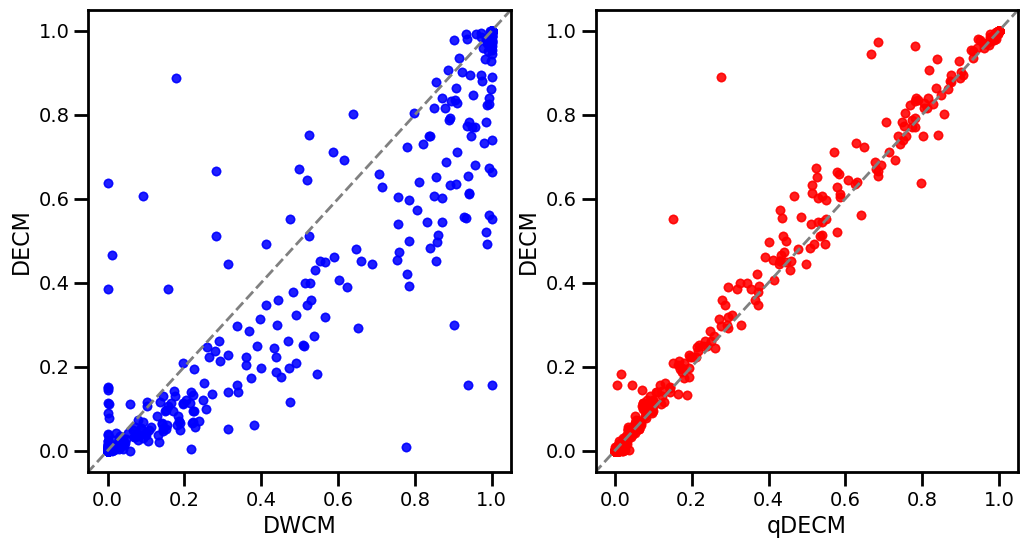

In [36]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].scatter(dwcm_p_values, decm_p_values, color='blue', alpha=0.5, label='DWCM vs DECM')
axs[1].scatter(qdecm_p_values, decm_p_values, color='red', alpha=0.5, label='qDECM vs DECM')
for i in range(2):
    axs[i].plot([-2, 2], [-2, 2], '--', lw=2, color='gray')
    axs[i].set_xlim(-0.05, 1.05)
    axs[i].set_ylim(-0.05, 1.05)
axs[0].set_xlabel('DWCM', fontsize=16)
axs[0].set_ylabel('DECM', fontsize=16)
axs[1].set_xlabel('qDECM', fontsize=16)
axs[1].set_ylabel('DECM', fontsize=16)
plt.show()

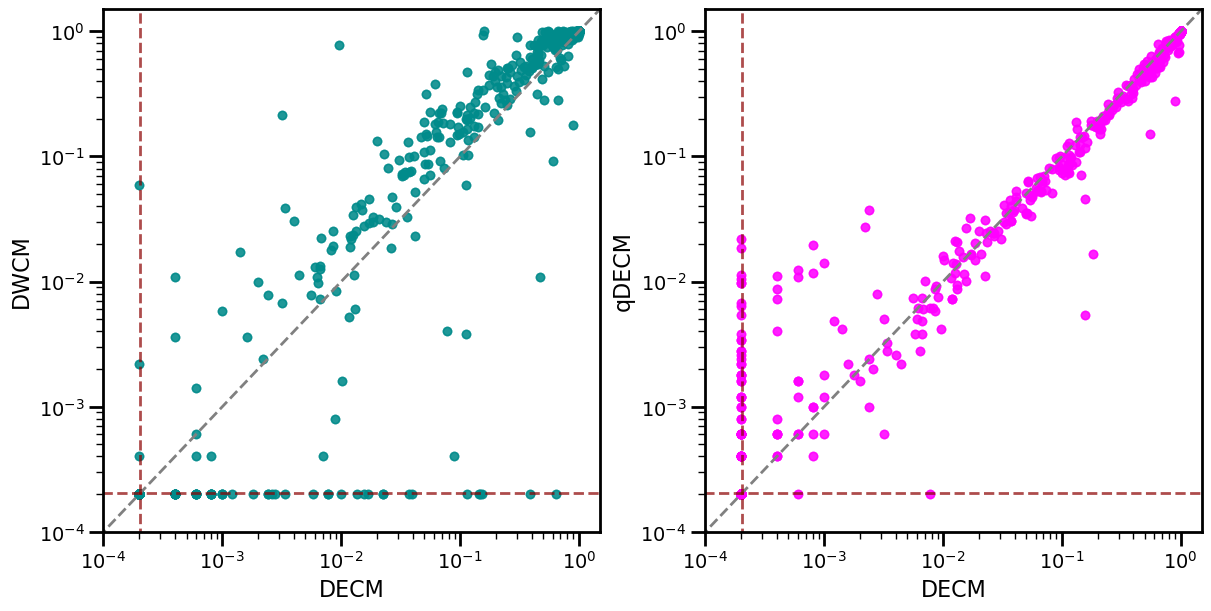

In [37]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6),layout="constrained")
axs[0].scatter(decm_p_values,dwcm_p_values, color='darkcyan', alpha=0.5)
axs[1].scatter(decm_p_values,qdecm_p_values, color='magenta', alpha=0.5)
for i in range(2):
    axs[i].plot([1e-5, 2], [1e-5, 2], '--', lw=2, color='gray')
    axs[i].hlines(ALPHA/n_flows, 1e-5, 1.5, colors='darkred', linestyles='--', linewidth=2, alpha=0.7, label=r'$\alpha_\text{Bonferroni}$')
    axs[i].vlines(ALPHA/n_flows, 1e-5, 1.5, colors='darkred', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].hlines(2*ALPHA/n_blocks, 1e-5, 1.5, colors='red', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].vlines(2*ALPHA/n_blocks, 1e-5, 1.5, colors='red', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].hlines(3*ALPHA/n_blocks, 1e-5, 1.5, colors='darkorange', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].vlines(3*ALPHA/n_blocks, 1e-5, 1.5, colors='darkorange', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].hlines(4*ALPHA/n_blocks, 1e-5, 1.5, colors='orange', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].vlines(4*ALPHA/n_blocks, 1e-5, 1.5, colors='orange', linestyles='--', linewidth=2, alpha=0.7)
                
    axs[i].set_xlim(1e-4, 1.5)
    axs[i].set_ylim(1e-4, 1.5)
    axs[i].set_xscale('log')
    axs[i].set_yscale('log')
    #axs[i].legend(fontsize=16)
axs[0].set_xlabel('DECM', fontsize=16)
axs[0].set_ylabel('DWCM', fontsize=16)
axs[1].set_xlabel('DECM', fontsize=16)
axs[1].set_ylabel('qDECM', fontsize=16)
plt.savefig(PLOT_FOLDER+f"p_value_flow_comparison.png", dpi=300)
plt.show()